In [2]:
# importing necessary modules that will be used in our script
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

I0000 00:00:1791962369.689695    4820 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791962377.371810    4820 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANEL = 3
EPOCHS = 50

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../training_dataset", # directory of your source dataset
    shuffle=True, #randomly shuffling images
    image_size = (IMAGE_SIZE, IMAGE_SIZE), # resize all images to have same dimensions
    batch_size = BATCH_SIZE # load 32 image for each batch
)

Found 2152 files belonging to 3 classes.


E0000 00:00:1791962385.561231    4820 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [6]:
len(dataset) # it runned 68 batches nd for every batch it is loading 32 image so 68 * 32 is 2176

68

In [7]:
for batch_image, label_batch in dataset.take(1):
    print(batch_image.shape)
    print(label_batch.numpy())
    # 0 is Potato___Early_blight, 1 is Potato___Late_blight and 2 is Potato___healthy just like array of our class_names

(32, 256, 256, 3)
[1 1 1 0 0 1 0 1 0 1 0 0 1 1 1 0 1 0 1 2 1 0 2 0 1 0 0 1 0 0 0 1]


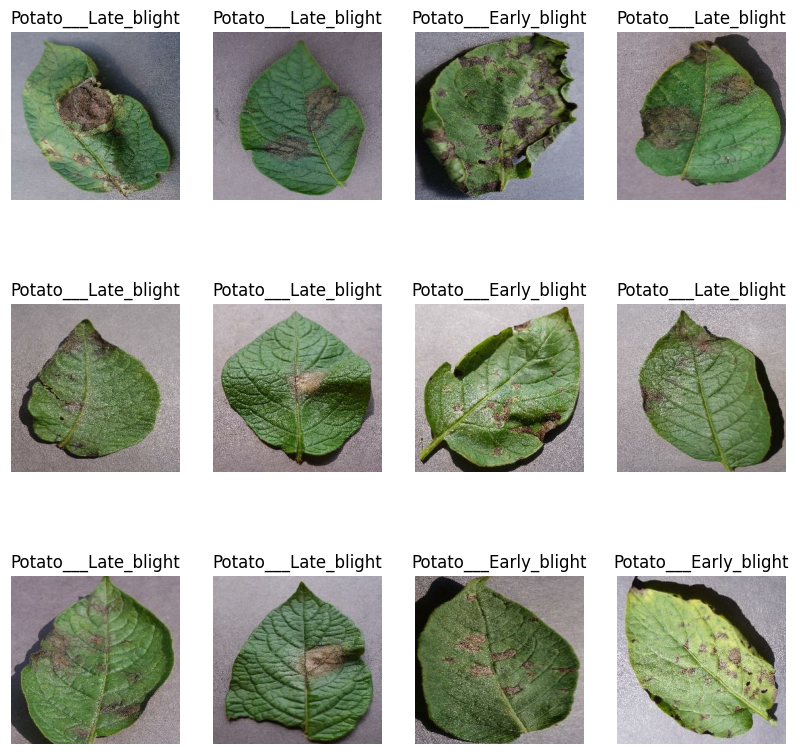

In [8]:
plt.figure(figsize=(10, 10))
for batch_image, label_batch in dataset.take(1):
    for i in range(12):
            #  i + 1 means space to be added btn the images, and 3 means three rows , 4 columns
            ax = plt.subplot(3, 4, i + 1)
            plt.axis("off") # hidding x axis numbers an y-axis numbers
            plt.imshow(batch_image[i].numpy().astype("uint8"))
            plt.title(class_names[label_batch[i]])
            # print(batch_image[0].numpy())

In [ ]:
# BIG OVERVIEW
80% ==> training
20% ==> 10% validation, 10% test

In [9]:
training_size = 0.8
len(dataset)*training_size

54.400000000000006

In [10]:
training_ds = dataset.take(54)

In [11]:
test_ds = dataset.skip(54)
len(test_ds)

14

In [12]:
validation = 0.1
len(dataset)*validation

6.800000000000001

In [13]:
validation_ds = test_ds.take(6)

In [14]:
test_ds = test_ds.skip(6)

In [15]:
def get_dataset_partition_tf(ds, train_split=0.8, validation_split=0.1, test_split=0.1, shuffle=True, shuffle_size=1000):
    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size)
    training_size = int(ds_size * train_split)
    validation_size = int(ds_size * validation_split)
    training_ds = ds.take(training_size)
    
    test_ds = ds.skip(training_size).take(validation_size)
    validation_ds = ds.skip(training_size).skip(validation_size)

    return training_ds, test_ds, validation_ds

In [16]:
training_ds, test_ds, validation_ds = get_dataset_partition_tf(dataset)

In [17]:
len(training_ds)

54

In [18]:
# better approach if you're building a big project with small RAM
training_ds = training_ds.prefetch(1)
test_ds = test_ds.prefetch(1)
validation_ds = validation_ds.prefetch(1)

In [19]:
# next step is image preprocessing (scale, resize)
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0/255)
])

In [20]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

In [21]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANEL)
model = tf.keras.Sequential([
    resize_and_rescale,
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation = "relu", input_shape = input_shape),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation = "relu"),
    layers.Dense(3, activation = "softmax")
])

model.build(input_shape=input_shape)

/home/etiene-niyomugabo123/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [22]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 28, 28, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 14, 14, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 12, 12, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 6, 6, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 4, 4, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (32, 2, 2, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 256)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 64)               │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 3)                │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [25]:
history = model.fit(
    training_ds,
    epochs=5,
    batch_size=BATCH_SIZE,
    verbose=1,
    validation_data=validation_ds,
    
)

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.7911 - loss: 0.5048 - val_accuracy: 0.8594 - val_loss: 0.4706
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.8478 - loss: 0.3676 - val_accuracy: 0.9336 - val_loss: 0.1870
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.8621 - loss: 0.3364 - val_accuracy: 0.9023 - val_loss: 0.2629
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.9103 - loss: 0.2311 - val_accuracy: 0.9336 - val_loss: 0.1783
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 139s 3s/step - accuracy: 0.9167 - loss: 0.2143 - val_accuracy: 0.9414 - val_loss: 0.1427


In [26]:
model.evaluate(test_ds)

6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 623ms/step - accuracy: 0.9271 - loss: 0.1345


[0.1345137506723404, 0.9270833134651184]

In [27]:
history.params

{'verbose': 1, 'epochs': 5, 'steps': 54}

In [28]:
history.history['accuracy']

[0.7910798192024231,
 0.8478009104728699,
 0.862089216709137,
 0.9103009104728699,
 0.9166666865348816]

In [33]:
acc = history.history['accuracy']
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

Text(0.5, 1.0, 'Training and validation Loss')

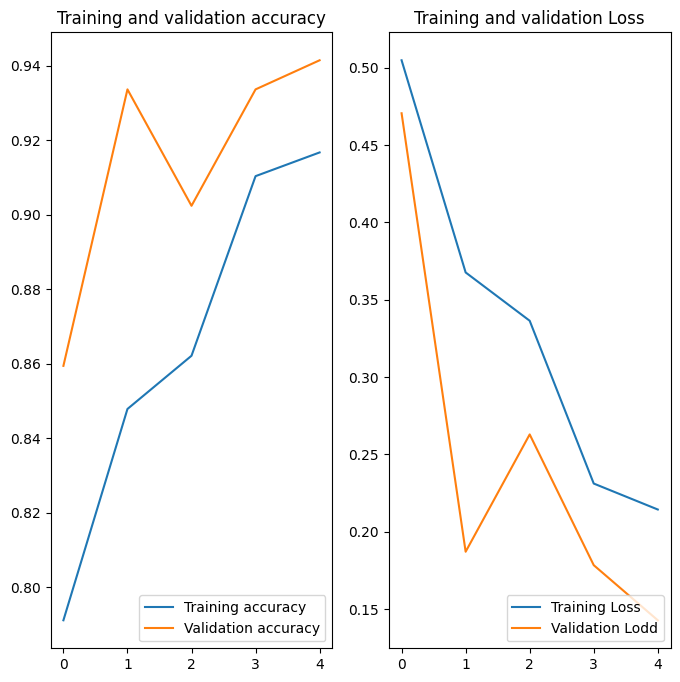

In [34]:
plt.figure(figsize = (8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(5), acc, label = "Training accuracy")
plt.plot(range(5), val_acc, label = "Validation accuracy")
plt.legend(loc="lower right")
plt.title("Training and validation accuracy")

plt.subplot(1, 2, 2)
plt.plot(range(5), loss, label = "Training Loss")
plt.plot(range(5), val_loss, label = "Validation Lodd")
plt.legend(loc="lower right")
plt.title("Training and validation Loss")

first image to predict
first image's actual label Potato___Late_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 698ms/step
Predicted label Potato___Late_blight


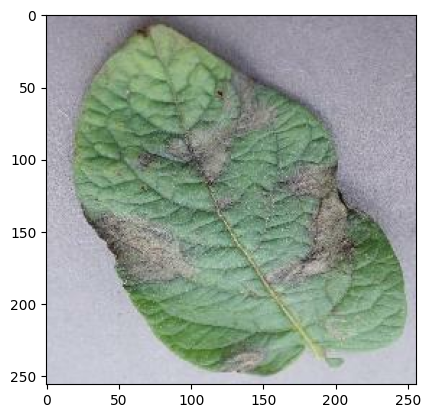

In [35]:
import numpy as np
for image_batch, label_batch in test_ds.take(1):
    first_image = image_batch[0].numpy().astype("uint8")
    first_label = label_batch[0]

    print("first image to predict")
    plt.imshow(first_image)
    print("first image's actual label", class_names[first_label])
    batch_prediction = model.predict(image_batch)
    print("Predicted label", class_names[np.argmax(batch_prediction[0])])

In [36]:
def predict(model, img):
    image_array = tf.keras.preprocessing.image_to_array(images[i].numpy())
    image_array = tf.expand_dim(image_array, 0)
    predictions = model.predict(image_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = np.round(100 * (np.max(predictions[0])), 2)
    return confidence, predicted_class